# CSCN8000 – Assignment 2: Boston Housing Regression Models

**Student:** Juan Antonio Sainz Gálvez (Antonio Sainz)
**Course:** CSCN8000 – Artificial Intelligence Algorithms and Mathematics
**Assignment:** Assignment 2 – Predicting the median value of owner-occupied homes (MEDV)

## 1. Objectives
- Preprocess the Boston Housing dataset (missing values, outliers, standardization).
- Split the data into 80% training and 20% test samples.
- Train seven supervised models: Linear Regression (multilinear), XGBoost, Decision Tree, Random Forest, Logistic Regression, Lasso (L1) and Ridge (L2).
- Predict MEDV on the test data, build a predictive system for a new sample, compare the models (Accuracy, MAE, R², RMSE) and save all test predictions to a single CSV file.

The workflow follows the Week 11 class notebook (*Linear, Multilinear, XGBoost, Decision Tree, Random Forest, Logistic, L1 and L2 Regressions*).

## 2. Setup and Required Libraries
The notebook runs in the project virtual environment (`.venv`) created from `requirements.txt`:
numpy, pandas, matplotlib, seaborn, scikit-learn, xgboost, jupyter.

The dataset file `data/boston_housing.csv` is the Kaggle Boston Housing data (506 rows, 13 features + MEDV),
saved with column names.

In [1]:
# import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Suppress warnings for a clean notebook
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 2  # same random_state used in the class notebook

In [2]:
# read dataset (relative path inside the assignment folder)
dataset = pd.read_csv('data/boston_housing.csv')
dataset.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


**Feature description**

| Column | Meaning |
|---|---|
| CRIM | Per-capita crime rate by town |
| ZN | Proportion of residential land zoned for lots over 25,000 sq.ft. |
| INDUS | Proportion of non-retail business acres per town |
| CHAS | Charles River dummy variable (1 if tract bounds river, 0 otherwise) |
| NOX | Nitric oxides concentration (parts per 10 million) |
| RM | Average number of rooms per dwelling |
| AGE | Proportion of owner-occupied units built before 1940 |
| DIS | Weighted distances to five Boston employment centres |
| RAD | Index of accessibility to radial highways |
| TAX | Full-value property-tax rate per $10,000 |
| PTRATIO | Pupil-teacher ratio by town |
| B | 1000(Bk − 0.63)² where Bk is the proportion of Black residents by town |
| LSTAT | % lower status of the population |
| **MEDV** | **Target: median value of owner-occupied homes in $1000's** |

In [3]:
print(dataset.shape)
dataset.info()

(506, 14)
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [4]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
ZN,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
INDUS,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
CHAS,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
AGE,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


## 3. Question 1 – Data Preprocessing
### 3.1 Checking for missing values

In [5]:
dataset.isna().sum()  # count of missing values (NaNs) in each column

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [6]:
print('Total missing values:', dataset.isna().sum().sum())
print('Duplicated rows     :', dataset.duplicated().sum())

Total missing values: 0
Duplicated rows     : 0


**Interpretation:** the dataset has no missing values and no duplicated rows, so no imputation or row removal is needed.

### 3.2 Checking for outliers
Two checks are used:
1. **Box plots** of every feature to visualize extreme values.
2. **Z-score rule (μ ± 3σ)** from the class Z-score notebook: a value with |z| > 3 lies outside the range that holds about 99.7% of the data and is considered an outlier.

`CHAS` is a binary 0/1 variable, so it is excluded from the Z-score check (its “outliers” are just the minority class).

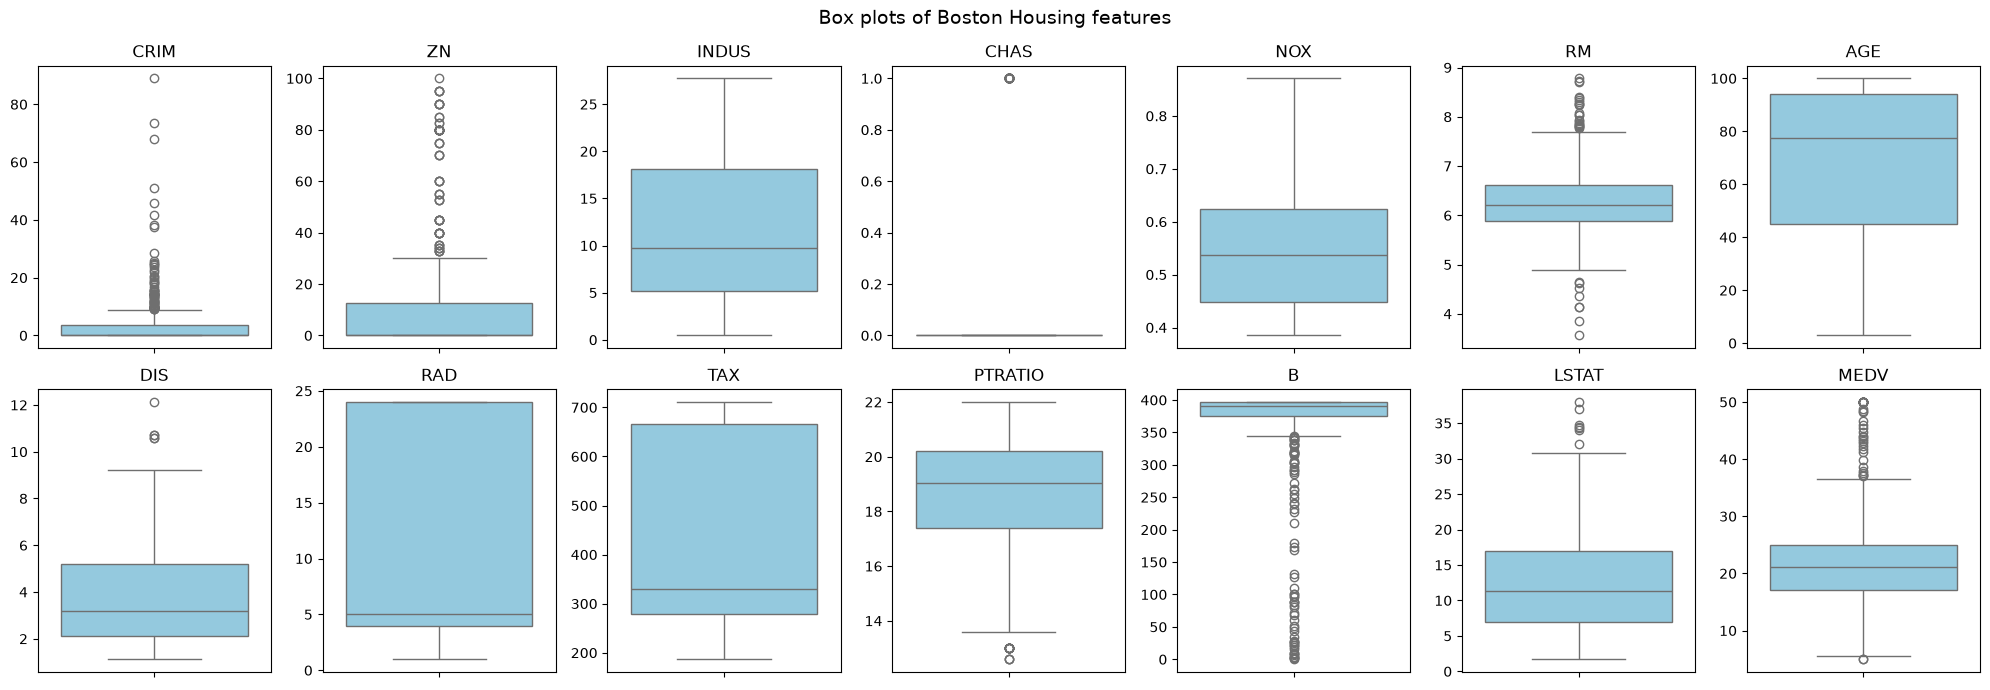

In [7]:
# Box plots of all columns to visualize outliers
fig, axes = plt.subplots(2, 7, figsize=(20, 7))
for ax, col in zip(axes.flatten(), dataset.columns):
    sns.boxplot(y=dataset[col], ax=ax, color='skyblue')
    ax.set_title(col)
    ax.set_ylabel('')
plt.suptitle('Box plots of Boston Housing features', fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
# Z-score outlier detection (|z| > 3), excluding the binary CHAS column
numeric_cols = dataset.columns.drop('CHAS')
z_scores = (dataset[numeric_cols] - dataset[numeric_cols].mean()) / dataset[numeric_cols].std()

outliers_per_column = (z_scores.abs() > 3).sum()
print('Outliers per column (|z| > 3):')
print(outliers_per_column)

rows_with_outliers = (z_scores.abs() > 3).any(axis=1)
print('\nRows with at least one outlier:', rows_with_outliers.sum(),
      f'({rows_with_outliers.mean():.1%} of the dataset)')

Outliers per column (|z| > 3):
CRIM        8
ZN         14
INDUS       0
NOX         0
RM          8
AGE         0
DIS         5
RAD         0
TAX         0
PTRATIO     0
B          25
LSTAT       5
MEDV        0
dtype: int64

Rows with at least one outlier: 58 (11.5% of the dataset)


In [9]:
# Rows flagged as outliers (first 10)
dataset[rows_with_outliers].head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
55,0.01311,90.0,1.22,0,0.4030,7.249,21.9,8.6966,5,226.0,17.9,395.93,4.81,35.4
56,0.02055,85.0,0.74,0,0.4100,6.383,35.7,9.1876,2,313.0,17.3,396.90,5.77,24.7
57,0.01432,100.0,1.32,0,0.4110,6.816,40.5,8.3248,5,256.0,15.1,392.90,3.95,31.6
102,0.22876,0.0,8.56,0,0.5200,6.405,85.4,2.7147,5,384.0,20.9,70.80,10.63,18.6
141,1.62864,0.0,21.89,0,0.6240,5.019,100.0,1.4394,4,437.0,21.2,396.90,34.41,14.4
199,0.03150,95.0,1.47,0,0.4030,6.975,15.3,7.6534,3,402.0,17.0,396.90,4.56,34.9
200,0.01778,95.0,1.47,0,0.4030,7.135,13.9,7.6534,3,402.0,17.0,384.30,4.45,32.9
201,0.03445,82.5,2.03,0,0.4150,6.162,38.4,6.2700,2,348.0,14.7,393.77,7.43,24.1
202,0.02177,82.5,2.03,0,0.4150,7.610,15.7,6.2700,2,348.0,14.7,395.38,3.11,42.3
203,0.03510,95.0,2.68,0,0.4161,7.853,33.2,5.1180,4,224.0,14.7,392.78,3.81,48.5


In [10]:
# Upper limit of the target: MEDV is capped at 50 in the original data
print('Rows with MEDV = 50:', (dataset['MEDV'] == 50).sum())

Rows with MEDV = 50: 16


**Decision on outliers:** the Z-score rule flags 58 rows (≈11% of a small 506-row dataset), mainly in CRIM, ZN, B, RM, DIS and LSTAT.
These are real neighbourhoods with skewed distributions (e.g., a few towns with very high crime rates), not data-entry errors,
and the target MEDV has no Z-score outliers. Removing 11% of the data would discard useful information, so **the outliers are
checked and reported but kept**. Standardization (next step) puts all features on the same scale, and the tree-based models
(Decision Tree, Random Forest, XGBoost) are naturally robust to extreme feature values.

### 3.3 Feature / target separation
More than one column in X → **Multiple (multilinear) Linear Regression**.

In [11]:
X = dataset.drop('MEDV', axis=1)  # 13 independent variables
y = dataset['MEDV']               # target: median home value in $1000's
print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (506, 13) | y shape: (506,)


## 4. Question 2 – Train/Test Split (80% training data)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
# test data = 20%, train data = 80%
print('Training samples:', X_train.shape[0], f'({X_train.shape[0]/len(X):.0%})')
print('Test samples    :', X_test.shape[0], f'({X_test.shape[0]/len(X):.0%})')

Training samples: 404 (80%)
Test samples    : 102 (20%)


### 4.1 Feature scaling (standardization)
`StandardScaler` transforms each feature to mean 0 and standard deviation 1: z = (x − μ) / σ.
The scaler is **fitted on the training data only** and the same scaler is applied to the test data, so no information from the test set leaks into training.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit on training data and transform it
X_test_scaled = scaler.transform(X_test)        # use the same scaler on test data

pd.DataFrame(X_train_scaled, columns=X.columns).describe().loc[['mean', 'std']].round(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
mean,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Question 3 – Model Training
All seven models are trained on the standardized training data.
A helper function computes the evaluation metrics used in the class notebook for every model.

In [14]:
def evaluate_model(name, model, X_te, y_te, y_pred):
    """Return accuracy (model.score), MAE, R-squared and RMSE for one model."""
    accuracy = model.score(X_te, y_te)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    print(f'{name}')
    print('  Accuracy (test score) =', round(accuracy, 4))
    print('  Mean Absolute Error   =', round(mae, 4))
    print('  R-Squared             =', round(r2, 4))
    print('  Root Mean Sq. Error   =', round(rmse, 4))
    return accuracy, mae, r2, rmse


def plot_actual_vs_predicted(y_pred, title):
    """Scatter plot of actual vs predicted MEDV with the ideal y = x line."""
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred, alpha=0.7)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='-')
    plt.xlabel('Actual MEDV ($1000s)')
    plt.ylabel('Predicted MEDV ($1000s)')
    plt.title(f'{title}: Actual vs Predicted')
    plt.show()

### 5.1 Linear Regression (multilinear)

In [15]:
reg = LinearRegression()
reg.fit(X_train_scaled, y_train)
print('Intercept:', round(reg.intercept_, 3))
pd.Series(reg.coef_, index=X.columns).round(3)

Intercept: 22.441


CRIM      -0.935
ZN         0.855
INDUS     -0.104
CHAS       0.815
NOX       -1.907
RM         2.547
AGE        0.259
DIS       -2.927
RAD        2.805
TAX       -1.957
PTRATIO   -2.159
B          1.092
LSTAT     -3.919
dtype: float64

### 5.2 XGBoost Regression

In [16]:
xgb_model = XGBRegressor(random_state=RANDOM_STATE)
xgb_model.fit(X_train_scaled, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### 5.3 Decision Tree Regression

In [17]:
dt_model = DecisionTreeRegressor(random_state=RANDOM_STATE)
dt_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

### 5.4 Random Forest Regression

In [18]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)
rf_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of

### 5.5 Logistic Regression
Logistic Regression is a **classification** algorithm and does not accept a continuous target such as MEDV (e.g., 21.6).
Following the class notebook, where Logistic Regression is trained directly on the price values, MEDV is rounded to the
nearest whole $1000 and each integer value is treated as a class. The predicted class is therefore a MEDV value that can be
evaluated with the same regression metrics (MAE, R², RMSE) as the other models.

In [19]:
y_train_int = y_train.round().astype(int)  # integer MEDV classes for Logistic Regression
y_test_int = y_test.round().astype(int)
print('Number of MEDV classes in training data:', y_train_int.nunique())

log_reg = LogisticRegression(max_iter=5000)
log_reg.fit(X_train_scaled, y_train_int)

Number of MEDV classes in training data: 45


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### 5.6 Lasso (L1 regularization)
L1 adds the penalty α·Σ|wᵢ| to the loss, which can shrink some coefficients exactly to zero (feature selection).

In [20]:
lasso_reg = Lasso(alpha=0.1, max_iter=10000)
lasso_reg.fit(X_train_scaled, y_train)
pd.Series(lasso_reg.coef_, index=X.columns).round(3)

CRIM      -0.668
ZN         0.485
INDUS     -0.187
CHAS       0.809
NOX       -1.368
RM         2.706
AGE        0.000
DIS       -2.317
RAD        1.431
TAX       -0.850
PTRATIO   -1.984
B          0.999
LSTAT     -3.844
dtype: float64

### 5.7 Ridge (L2 regularization)
L2 adds the penalty α·Σwᵢ² to the loss, which shrinks all coefficients towards zero without removing them.

In [21]:
ridge_reg = Ridge(alpha=1.0)
ridge_reg.fit(X_train_scaled, y_train)
pd.Series(ridge_reg.coef_, index=X.columns).round(3)

CRIM      -0.926
ZN         0.839
INDUS     -0.127
CHAS       0.820
NOX       -1.876
RM         2.557
AGE        0.250
DIS       -2.895
RAD        2.724
TAX       -1.886
PTRATIO   -2.146
B          1.090
LSTAT     -3.903
dtype: float64

## 6. Question 4 – Predicting MEDV on the Test Data
Each model predicts the median value of owner-occupied homes (in $1000's) for the 102 test samples.

In [22]:
y_pred_lr = reg.predict(X_test_scaled)
y_pred_xgb = xgb_model.predict(X_test_scaled)
y_pred_dt = dt_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_logr = log_reg.predict(X_test_scaled)
y_pred_lasso = lasso_reg.predict(X_test_scaled)
y_pred_rdg = ridge_reg.predict(X_test_scaled)

# First 10 test predictions side by side with the actual MEDV
first_predictions = pd.DataFrame({
    'Actual_MEDV': y_test.values,
    'Linear_Regression': y_pred_lr,
    'XGBoost': y_pred_xgb,
    'Decision_Tree': y_pred_dt,
    'Random_Forest': y_pred_rf,
    'Logistic_Regression': y_pred_logr,
    'Lasso_L1': y_pred_lasso,
    'Ridge_L2': y_pred_rdg,
}).round(2)
first_predictions.head(10)

,Actual_MEDV,Linear_Regression,XGBoost,Decision_Tree,Random_Forest,Logistic_Regression,Lasso_L1,Ridge_L2
0,20.2,23.02,22.790001,20.0,21.78,23,22.96,23.00
1,15.3,21.21,21.540001,20.8,20.85,23,21.94,21.25
2,37.3,33.72,29.980000,28.5,32.50,28,32.52,33.65
3,32.5,31.57,28.790001,36.2,29.62,20,30.40,31.51
4,8.8,3.18,9.400000,7.2,8.24,12,2.94,3.18
5,14.4,3.15,14.210000,17.8,13.75,14,3.69,3.21
6,22.0,27.40,23.980000,31.0,27.56,24,27.09,27.39
7,26.6,22.21,25.170000,29.6,29.30,33,23.91,22.32
8,15.0,14.87,22.379999,11.7,30.91,9,15.38,14.84
9,21.5,21.34,20.110001,19.6,20.49,23,22.27,21.38


### 6.1 Actual vs predicted plots
Points close to the red line (y = x) are accurate predictions.

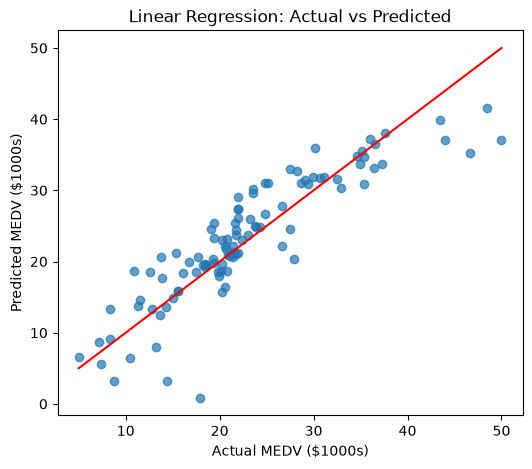

In [23]:
plot_actual_vs_predicted(y_pred_lr, 'Linear Regression')

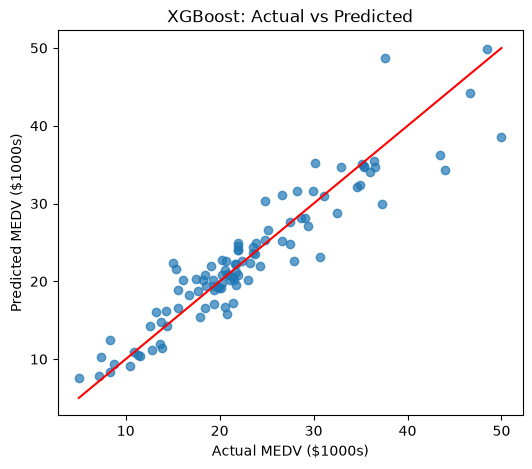

In [24]:
plot_actual_vs_predicted(y_pred_xgb, 'XGBoost')

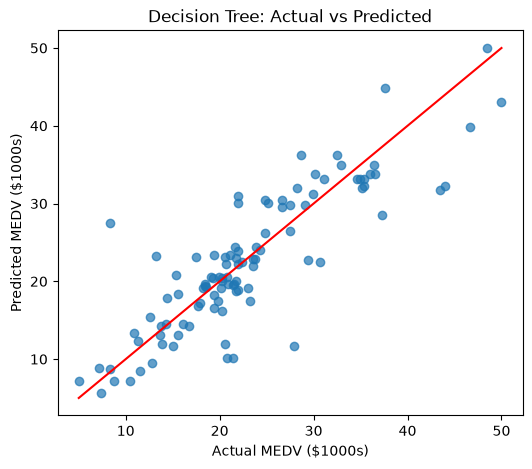

In [25]:
plot_actual_vs_predicted(y_pred_dt, 'Decision Tree')

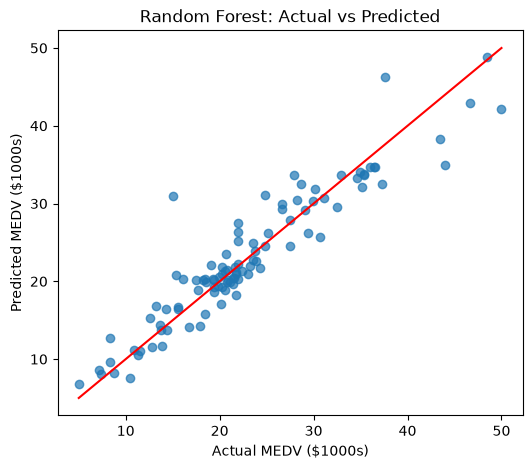

In [26]:
plot_actual_vs_predicted(y_pred_rf, 'Random Forest')

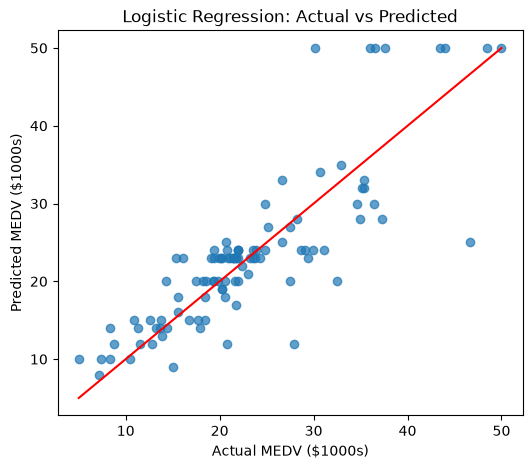

In [27]:
plot_actual_vs_predicted(y_pred_logr, 'Logistic Regression')

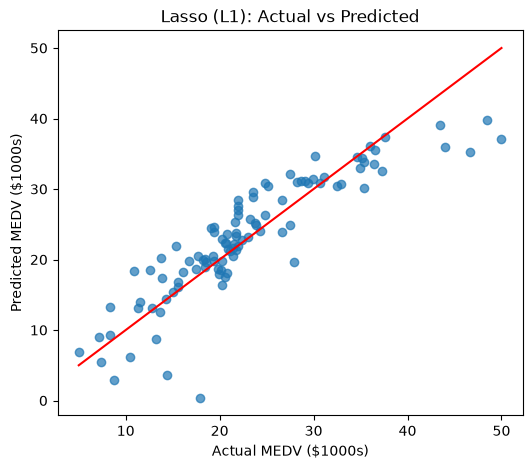

In [28]:
plot_actual_vs_predicted(y_pred_lasso, 'Lasso (L1)')

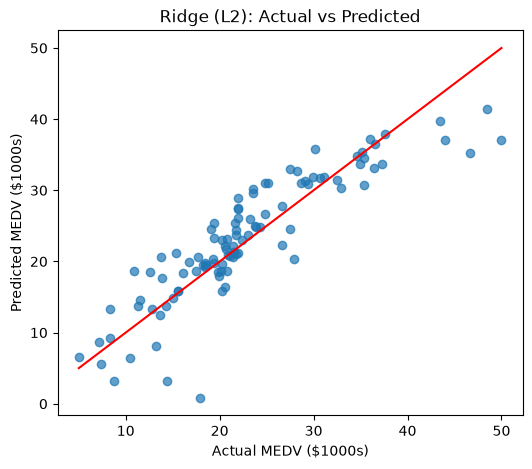

In [29]:
plot_actual_vs_predicted(y_pred_rdg, 'Ridge (L2)')

## 7. Question 5 – Predictive System for a New Sample
The predictive system receives the 13 feature values of a new house, applies the **same scaler** fitted on the training data,
and returns the MEDV predicted by every model.

In [30]:
models = {
    'Linear Regression': reg,
    'XGBoost': xgb_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Logistic Regression': log_reg,
    'Lasso (L1)': lasso_reg,
    'Ridge (L2)': ridge_reg,
}


def predict_medv(new_sample):
    """Predict MEDV ($1000's) for one new house with every trained model."""
    sample_df = pd.DataFrame([new_sample], columns=X.columns)  # keep the training column order
    sample_scaled = scaler.transform(sample_df)
    predictions = {name: float(model.predict(sample_scaled)[0]) for name, model in models.items()}
    return pd.Series(predictions, name='Predicted MEDV ($1000s)').round(3)

**Verification 1 – a known house from the test set.** The system is first checked on a test house whose real MEDV is known.

In [31]:
known_house = X_test.iloc[0].to_dict()
print('Actual MEDV of this house:', y_test.iloc[0])
predict_medv(known_house)

Actual MEDV of this house: 20.2


Linear Regression      23.015
XGBoost                22.787
Decision Tree          20.000
Random Forest          21.780
Logistic Regression    23.000
Lasso (L1)             22.957
Ridge (L2)             23.003
Name: Predicted MEDV ($1000s), dtype: float64

**Verification 2 – a completely new house.** A new 6.5-room home in a low-crime area, near employment centres, with a moderate tax rate.

In [32]:
new_house = {
    'CRIM': 0.05, 'ZN': 12.5, 'INDUS': 5.0, 'CHAS': 0, 'NOX': 0.45,
    'RM': 6.5, 'AGE': 45.0, 'DIS': 5.0, 'RAD': 4, 'TAX': 300.0,
    'PTRATIO': 17.0, 'B': 390.0, 'LSTAT': 7.0,
}
new_house_predictions = predict_medv(new_house)
print('Predicted median value for the new house:')
print((new_house_predictions * 1000).map('${:,.0f}'.format))

Predicted median value for the new house:
Linear Regression      $28,055
XGBoost                $24,059
Decision Tree          $22,600
Random Forest          $23,844
Logistic Regression    $24,000
Lasso (L1)             $28,052
Ridge (L2)             $28,051
Name: Predicted MEDV ($1000s), dtype: str


## 8. Question 6 – Model Evaluation and Best Model
Metrics used (same as the class notebook):
- **Accuracy:** `model.score()` on the test data. For the regression models it is the R²; for Logistic Regression it is the classification accuracy (share of houses whose rounded MEDV class is predicted exactly).
- **MAE (Mean Absolute Error):** average absolute difference between actual and predicted MEDV, in $1000's.
- **R² (Coefficient of Determination):** share of the variance of MEDV explained by the model (1 = perfect).
- **RMSE (Root Mean Squared Error):** square root of the average squared error, in $1000's; penalizes large errors.

In [33]:
lr_accuracy, mae_lr, r2_lr, rmse_lr = evaluate_model('Linear Regression', reg, X_test_scaled, y_test, y_pred_lr)
xgb_accuracy, mae_xgb, r2_xgb, rmse_xgb = evaluate_model('XGBoost', xgb_model, X_test_scaled, y_test, y_pred_xgb)
dt_accuracy, mae_dt, r2_dt, rmse_dt = evaluate_model('Decision Tree', dt_model, X_test_scaled, y_test, y_pred_dt)
rf_accuracy, mae_rf, r2_rf, rmse_rf = evaluate_model('Random Forest', rf_model, X_test_scaled, y_test, y_pred_rf)
logr_accuracy, mae_logr, r2_logr, rmse_logr = evaluate_model('Logistic Regression', log_reg, X_test_scaled, y_test_int, y_pred_logr)
lasso_accuracy, mae_lasso, r2_lasso, rmse_lasso = evaluate_model('Lasso (L1)', lasso_reg, X_test_scaled, y_test, y_pred_lasso)
rdg_accuracy, mae_rdg, r2_rdg, rmse_rdg = evaluate_model('Ridge (L2)', ridge_reg, X_test_scaled, y_test, y_pred_rdg)

Linear Regression
  Accuracy (test score) = 0.7789
  Mean Absolute Error   = 3.113
  R-Squared             = 0.7789
  Root Mean Sq. Error   = 4.3006
XGBoost
  Accuracy (test score) = 0.8771
  Mean Absolute Error   = 2.2488
  R-Squared             = 0.8771
  Root Mean Sq. Error   = 3.2064
Decision Tree
  Accuracy (test score) = 0.7204
  Mean Absolute Error   = 3.3843
  R-Squared             = 0.7204
  Root Mean Sq. Error   = 4.8364
Random Forest
  Accuracy (test score) = 0.8795
  Mean Absolute Error   = 2.2077
  R-Squared             = 0.8795
  Root Mean Sq. Error   = 3.1754
Logistic Regression
  Accuracy (test score) = 0.1275
  Mean Absolute Error   = 3.6892
  R-Squared             = 0.6443
  Root Mean Sq. Error   = 5.4548
Lasso (L1)
  Accuracy (test score) = 0.7811
  Mean Absolute Error   = 3.0694
  R-Squared             = 0.7811
  Root Mean Sq. Error   = 4.2794
Ridge (L2)
  Accuracy (test score) = 0.7791
  Mean Absolute Error   = 3.1089
  R-Squared             = 0.7791
  Root Mean Sq

### 8.1 Accuracies, R², MAE and RMSE for all the models

In [34]:
accuracies_models = pd.DataFrame({
    'Models': ['Linear Regression', 'Lasso Regression', 'Ridge Regression', 'XGBoost Regression',
               'Decision Tree Regression', 'Random Forest Regression', 'Logistic Regression'],
    'Accuracies': [lr_accuracy, lasso_accuracy, rdg_accuracy, xgb_accuracy, dt_accuracy, rf_accuracy, logr_accuracy],
    'R^2': [r2_lr, r2_lasso, r2_rdg, r2_xgb, r2_dt, r2_rf, r2_logr],
    'MAE': [mae_lr, mae_lasso, mae_rdg, mae_xgb, mae_dt, mae_rf, mae_logr],
    'RMSE': [rmse_lr, rmse_lasso, rmse_rdg, rmse_xgb, rmse_dt, rmse_rf, rmse_logr],
})
accuracies_models = accuracies_models.sort_values('Accuracies', ascending=False).reset_index(drop=True)
accuracies_models.round(4)

,Models,Accuracies,R^2,MAE,RMSE
0,Random Forest Regression,0.8795,0.8795,2.2077,3.1754
1,XGBoost Regression,0.8771,0.8771,2.2488,3.2064
2,Lasso Regression,0.7811,0.7811,3.0694,4.2794
3,Ridge Regression,0.7791,0.7791,3.1089,4.2985
4,Linear Regression,0.7789,0.7789,3.1130,4.3006
5,Decision Tree Regression,0.7204,0.7204,3.3843,4.8364
6,Logistic Regression,0.1275,0.6443,3.6892,5.4548


In [35]:
best_model = accuracies_models.iloc[0]
print(f"Best model (highest accuracy): {best_model['Models']}")
print(f"  Accuracy = {best_model['Accuracies']:.4f} | R^2 = {best_model['R^2']:.4f} | "
      f"MAE = {best_model['MAE']:.4f} | RMSE = {best_model['RMSE']:.4f}")

Best model (highest accuracy): Random Forest Regression
  Accuracy = 0.8795 | R^2 = 0.8795 | MAE = 2.2077 | RMSE = 3.1754


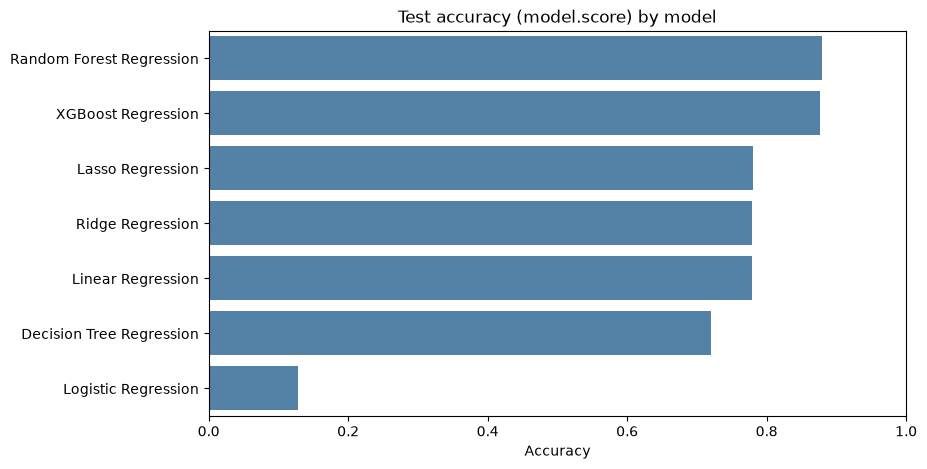

In [36]:
# Accuracy comparison chart
plt.figure(figsize=(9, 5))
sns.barplot(data=accuracies_models, x='Accuracies', y='Models', color='steelblue')
plt.title('Test accuracy (model.score) by model')
plt.xlabel('Accuracy')
plt.ylabel('')
plt.xlim(0, 1)
plt.show()

### 8.2 Summary of the evaluation metrics
| Model | Accuracy (score) | R² | MAE ($1000s) | RMSE ($1000s) |
|---|---|---|---|---|
| Random Forest | 0.8795 | 0.8795 | 2.21 | 3.18 |
| XGBoost | 0.8771 | 0.8771 | 2.25 | 3.21 |
| Lasso (L1) | 0.7811 | 0.7811 | 3.07 | 4.28 |
| Ridge (L2) | 0.7791 | 0.7791 | 3.11 | 4.30 |
| Linear Regression | 0.7789 | 0.7789 | 3.11 | 4.30 |
| Decision Tree | 0.7204 | 0.7204 | 3.38 | 4.84 |
| Logistic Regression | 0.1275 (class accuracy) | 0.6443 | 3.69 | 5.45 |

- **Best model: Random Forest Regression** – highest accuracy (R² = 0.88), lowest MAE (≈ $2,208) and lowest RMSE (≈ $3,175). It explains about 88% of the variance in MEDV.
- **XGBoost** is almost tied with Random Forest (R² = 0.877, MAE ≈ $2,249). Both ensemble methods capture the non-linear relationships (e.g., between RM, LSTAT and MEDV) that linear models cannot.
- **Linear, Lasso and Ridge** perform almost identically (R² ≈ 0.78, MAE ≈ $3,100). With only 13 standardized features and 404 training samples there is little overfitting, so L1/L2 regularization changes the results very little; Lasso is marginally best of the three.
- **Decision Tree** (a single, unpruned tree) overfits the training data and has the lowest R² of the regression models (0.72); averaging many trees (Random Forest) fixes this.
- **Logistic Regression** is a classifier: its accuracy (12.75%) only counts houses whose rounded MEDV is predicted *exactly*, among 45 possible classes. Measured as a regressor its predictions are still reasonable (R² = 0.64, MAE ≈ $3,689), but it is the weakest model because it ignores the order and distance between price values.
- The actual-vs-predicted plots show that all models underestimate the most expensive homes (MEDV = 50, the dataset's upper cap), the same high-end underestimation pattern seen in the class Melbourne example.

## 9. Question 7 – Saving the Test Predictions of All Models
All test-set predictions are saved in one CSV file, together with the test features and the actual MEDV.

In [37]:
os.makedirs('outputs', exist_ok=True)

test_predictions = X_test.copy()
test_predictions['Actual_MEDV'] = y_test.values
test_predictions['Pred_Linear_Regression'] = y_pred_lr
test_predictions['Pred_XGBoost'] = y_pred_xgb
test_predictions['Pred_Decision_Tree'] = y_pred_dt
test_predictions['Pred_Random_Forest'] = y_pred_rf
test_predictions['Pred_Logistic_Regression'] = y_pred_logr
test_predictions['Pred_Lasso_L1'] = y_pred_lasso
test_predictions['Pred_Ridge_L2'] = y_pred_rdg

csv_path = 'outputs/Antonio_Sainz_Assignment_2_test_predictions.csv'
test_predictions.round(4).to_csv(csv_path, index_label='Original_Index')
print('Saved:', csv_path, '| shape:', test_predictions.shape)
pd.read_csv(csv_path).head()

Saved: outputs/Antonio_Sainz_Assignment_2_test_predictions.csv | shape: (102, 21)


,Original_Index,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,...,B,LSTAT,Actual_MEDV,Pred_Linear_Regression,Pred_XGBoost,Pred_Decision_Tree,Pred_Random_Forest,Pred_Logistic_Regression,Pred_Lasso_L1,Pred_Ridge_L2
0,463,5.8212,0.0,18.10,0,0.713,6.513,89.9,2.8016,24,...,393.82,10.29,20.2,23.0151,22.7870,20.0,21.780,23,22.9575,23.0032
1,152,1.1266,0.0,19.58,1,0.871,5.012,88.0,1.6102,5,...,343.28,12.12,15.3,21.2116,21.5390,20.8,20.850,23,21.9356,21.2511
2,291,0.0789,80.0,4.95,0,0.411,7.148,27.7,5.1167,4,...,396.90,3.56,37.3,33.7159,29.9782,28.5,32.502,28,32.5161,33.6530
3,183,0.1001,0.0,2.46,0,0.488,6.563,95.6,2.8470,3,...,396.90,5.68,32.5,31.5654,28.7926,36.2,29.619,20,30.4047,31.5077
4,384,20.0849,0.0,18.10,0,0.700,4.368,91.2,1.4395,24,...,285.83,30.63,8.8,3.1826,9.4046,7.2,8.240,12,2.9368,3.1802


## 10. Conclusion
- The Boston Housing data had **no missing values or duplicates**. The Z-score rule (μ ± 3σ) flagged 58 rows with extreme feature values; they were reported and kept because they are real observations and represent 11% of a small dataset. All features were standardized with a scaler fitted on the 80% training split.
- Seven models were trained and used to predict MEDV for the 102 test houses. **Random Forest Regression is the best model** (accuracy/R² = 0.88, MAE ≈ $2.2k, RMSE ≈ $3.2k), followed closely by XGBoost.
- The **predictive system** (`predict_medv`) takes the 13 features of a new house, applies the same scaler and returns the MEDV predicted by every model. On a known test house (actual MEDV = $20,200) the Random Forest predicted ≈ $21,780, and for a new 6.5-room house in a low-crime area the ensemble models predict about $24,000.
- All test predictions were saved in one CSV file: `outputs/Antonio_Sainz_Assignment_2_test_predictions.csv`.
- Ensemble tree methods are the best choice for this kind of tabular, non-linear real-estate data; linear models remain useful for their interpretability (coefficients), and Logistic Regression is not suitable for a continuous target.